# Mountain CarをDPで解く

In [1]:
import numpy as np

def step(x, v, a):  # a: 0=左, 1=なし, 2=右
    v = v + (a - 1) * 0.001 - 0.0025 * np.cos(3 * x)
    v = np.clip(v, -0.07, 0.07)
    x = x + v
    x = np.clip(x, -1.2, 0.6)
    if x == -1.2 and v < 0:
        v = 0.0          # 左の壁にぶつかったら止まる
    done = x >= 0.5      # 旗の位置
    return x, v, done

def k_step(x, v, a, k):
    r = 0
    for _ in range(k):
        x, v, done = step(x, v, a)
        r -= 1
        if done:
            break
    return x, v, r, done

In [2]:
from itertools import product
import numpy as np

gamma = 0.99
theta = 1e-3
N = 400 # 状態の分割数
k = 8 # 飛ばすステップ数

xs = np.linspace(-1.2, 0.6, N)      # 位置の格子点
vs = np.linspace(-0.07, 0.07, N)    # 速度の格子点
states = [[(x, v) for v in vs] for x in xs]
indices = list(product(range(N), range(N)))
actions = [0, 1, 2] # 左、何もしない、右

V = np.zeros((N, N))

In [3]:
X_MIN, X_MAX, NX = -1.2, 0.6, N
DX = (X_MAX - X_MIN) / NX   # 0.018

def x_to_i(x):
    i = int((x - X_MIN) / DX)
    return min(i, NX - 1)    # x = 0.6 ちょうどだと N になるので押し戻す

V_MIN, V_MAX, NV = -0.07, 0.07, N
DV = (V_MAX - V_MIN) / NV   # 0.0014

def v_to_j(v):
    j = int((v - V_MIN) / DV)
    return min(j, NV - 1)    # v = 0.07 ちょうどだと N になるので押し戻す

def x_v_to_state(x, v):
    i = x_to_i(x)
    j = v_to_j(v)
    return (i, j)

def get_value(s):
    i, j = s
    return V[i][j]

def set_value(s, v):
    i, j = s
    V[i][j] = v

def get_next_state(s, a):
    i, j = s
    x, v = states[i][j]
    x, v , r, done = k_step(x, v, a, k)

    return x_v_to_state(x, v), r, done


# 最初に1回だけ: 遷移表を作る
trans = {}
for s in indices:
    for a in actions:
        trans[(s, a)] = get_next_state(s, a)   # (next_s, r, done)


def get_max_value(s):
    vs = []
    for a in actions:
        next_s, r, done = trans[(s, a)]
        if done:
            v = r
        else:
            v = r + gamma*get_value(next_s)
        vs.append(v)

    return max(vs)



In [4]:
while True:
    max_delta = 0
    for s in indices:
        v = get_value(s)
        new_v = get_max_value(s)
        set_value(s, new_v)
        max_delta = max(max_delta, abs(new_v - v))

    if max_delta < theta:
        break

In [6]:
def best_action(s):
    def q(a):
        next_s, r, done = trans[(s, a)]
        return r if done else r + gamma * get_value(next_s)
    return max(actions, key=q)

In [8]:
import gymnasium as gym

env = gym.make("MountainCar-v0", render_mode="human")
obs, _ = env.reset(seed=1)

steps = 0
done = False
while not done:
    s = x_v_to_state(obs[0], obs[1])
    a = best_action(s)
    for _ in range(k):          # 表は「同じ行動をk回続ける」前提で作ったので、本番もk回続ける
        obs, r, terminated, truncated, _ = env.step(a)
        steps += 1
        done = terminated or truncated
        if done:
            break

print("steps:", steps, "goal:", terminated)
env.close()

steps: 103 goal: True


## 平均

In [8]:
import gymnasium as gym
import numpy as np

def run_episode(env, seed):
    obs, _ = env.reset(seed=seed)
    steps = 0
    terminated = truncated = False
    while not (terminated or truncated):
        a = best_action(x_v_to_state(obs[0], obs[1]))
        for _ in range(k):
            obs, r, terminated, truncated, _ = env.step(a)
            steps += 1
            if terminated or truncated:
                break
    return steps, terminated

env = gym.make("MountainCar-v0")   # 描画なし
results = [run_episode(env, seed) for seed in range(100)]
env.close()

steps = np.array([s for s, _ in results])
goal = np.array([g for _, g in results])

print(f"成功率: {goal.mean():.0%}")
print(f"平均ステップ（成功のみ）: {steps[goal].mean():.1f}")
print(f"最悪ステップ（成功のみ）: {steps[goal].max()}")

成功率: 100%
平均ステップ（成功のみ）: 97.9
最悪ステップ（成功のみ）: 108


## 可視化

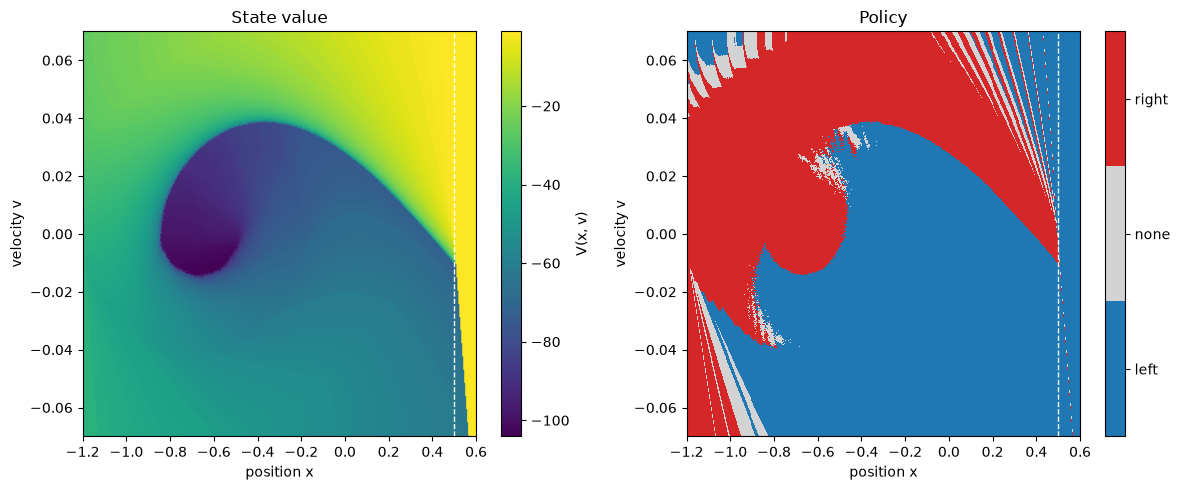

In [141]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 方策の表（best_action の引数は自分の実装に合わせて）
pi = np.zeros((N, N), dtype=int)
for i, j in indices:
    pi[i, j] = best_action((i, j))

extent = [xs[0], xs[-1], vs[0], vs[-1]]   # 軸の目盛りを実際の x, v にする
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 左: 状態価値
im = axes[0].imshow(V.T, origin="lower", extent=extent, aspect="auto", cmap="viridis")
fig.colorbar(im, ax=axes[0], label="V(x, v)")
axes[0].set_title("State value")

# 右: 方策（3色）
cmap = ListedColormap(["tab:blue", "lightgray", "tab:red"])   # 左, なし, 右
im2 = axes[1].imshow(pi.T, origin="lower", extent=extent, aspect="auto",
                     cmap=cmap, vmin=-0.5, vmax=2.5, interpolation="nearest")
cbar = fig.colorbar(im2, ax=axes[1], ticks=[0, 1, 2])
cbar.ax.set_yticklabels(["left", "none", "right"])
axes[1].set_title("Policy")

for ax in axes:
    ax.set_xlabel("position x")
    ax.set_ylabel("velocity v")
    ax.axvline(0.5, color="white", ls="--", lw=1)   # ゴールの位置

plt.tight_layout()
plt.show()

## GIFとして書き出す

In [10]:
import gymnasium as gym
from PIL import Image

env = gym.make(
    "MountainCar-v0", render_mode="rgb_array"
)  # 画面に出さず、画像として受け取る
obs, _ = env.reset(seed=1)

frames = [env.render()]  # 最初の1枚
steps = 0
done = False
while not done:
    a = best_action(x_v_to_state(obs[0], obs[1]))
    for _ in range(k):
        obs, r, terminated, truncated, _ = env.step(a)
        frames.append(env.render())  # 1ステップごとに1枚
        steps += 1
        done = terminated or truncated
        if done:
            break
env.close()

images = [Image.fromarray(f) for f in frames]
images[0].save(
    "mountaincar.gif",
    save_all=True,
    append_images=images[1:],
    duration=33,  # 1枚あたりのミリ秒。33で約30fps
    loop=0,  # 0で無限ループ
)
print("steps:", steps, "goal:", terminated, "frames:", len(frames))

steps: 103 goal: True frames: 104
